# Survivorship audit — the funding-carry universe over time

We backfilled the **survivorship-clean** universe: every USDT-margined perp that *ever* traded and
also has a spot pair (so it's hedgeable), including **delisted** names — 466 pairs, 2021-01..2026-06.
This notebook asks three things, all read from the lake (`query.coverage` / `query.get`), inferring
each name's listing/delisting **point-in-time from its own data coverage** (no metadata table):

1. **How many pairs are tradeable over time** — the listing/delisting waves.
2. **The cross-sectional funding-APR distribution** across the universe — where the carry lives.
3. **The delisted-name bias** — how much of the historical high-funding opportunity came from names
   that later died, i.e. how badly a *live-only* study (survivors only) misstates the edge.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import sys; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data import query
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,GREEN,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','#2d6a4f','0.65'

# Point-in-time coverage of each leg. A carry position needs ALL THREE: perp funding, perp 1h,
# spot 1h. The tradeable window of a name is the intersection of the three coverages.
cov_f  = query.coverage('perps','binance','funding_rate')
cov_pb = query.coverage('perps','binance','bars', timeframe='1h')
cov_sb = query.coverage('spot','binance','bars', timeframe='1h')
cov = pd.DataFrame({
    'first': pd.concat([cov_f['first'],cov_pb['first'],cov_sb['first']],axis=1).max(axis=1),
    'last' : pd.concat([cov_f['last'], cov_pb['last'], cov_sb['last']], axis=1).min(axis=1),
}).dropna()
END = cov['last'].max().normalize()
cov['alive_at_end'] = cov['last'] >= END - pd.Timedelta(days=30)   # still trading at the sample edge
cov['life_days'] = (cov['last'] - cov['first']).dt.days
print(f'tradeable pairs (all 3 legs): {len(cov)}  |  data end: {END.date()}')
print(f'alive at end: {int(cov.alive_at_end.sum())}  |  eventually delisted: {int((~cov.alive_at_end).sum())}')
cov.sort_values("first").head(3)

tradeable pairs (all 3 legs): 466  |  data end: 2026-05-31
alive at end: 368  |  eventually delisted: 98


,first,last,alive_at_end,life_days
symbol,,,,
zrxusdt,2021-01-01 00:00:00.002,2026-05-31 23:00:00,True,1976
ltcusdt,2021-01-01 00:00:00.002,2026-05-31 23:00:00,True,1976
compusdt,2021-01-01 00:00:00.002,2026-05-31 23:00:00,True,1976


## 1. How many pairs are tradeable over time

For each month, count the names whose tradeable window (all three legs live) covers it — split into
those **still alive** at the sample edge vs those **eventually delisted**. The delisted band is the
part of history a live-only universe erases.

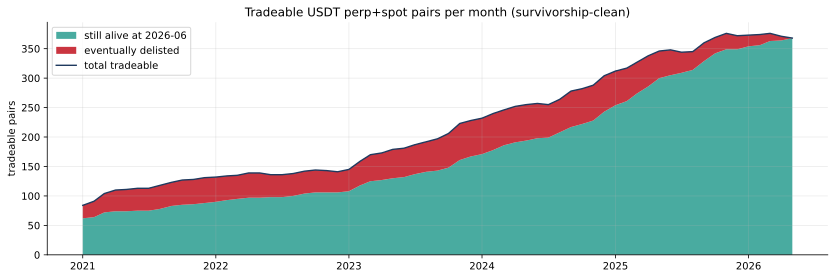

peak simultaneous tradeable pairs: 376


In [2]:
months = pd.date_range(cov['first'].min().normalize().replace(day=1), END, freq='MS')
def active_mask(m):
    m_end = m + pd.offsets.MonthEnd(0)
    return (cov['first'] <= m_end) & (cov['last'] >= m)
alive = np.array([int((active_mask(m) & cov.alive_at_end).sum()) for m in months])
dead  = np.array([int((active_mask(m) & ~cov.alive_at_end).sum()) for m in months])
fig, ax = plt.subplots(figsize=(14,4.2))
ax.stackplot(months, alive, dead, colors=[TEAL,RED], alpha=0.85,
             labels=['still alive at 2026-06','eventually delisted'])
ax.plot(months, alive+dead, color=NAVY, lw=1.4, label='total tradeable')
ax.set_ylabel('tradeable pairs'); ax.legend(loc='upper left')
ax.set_title('Tradeable USDT perp+spot pairs per month (survivorship-clean)')
plt.show()
print(f'peak simultaneous tradeable pairs: {int((alive+dead).max())}')

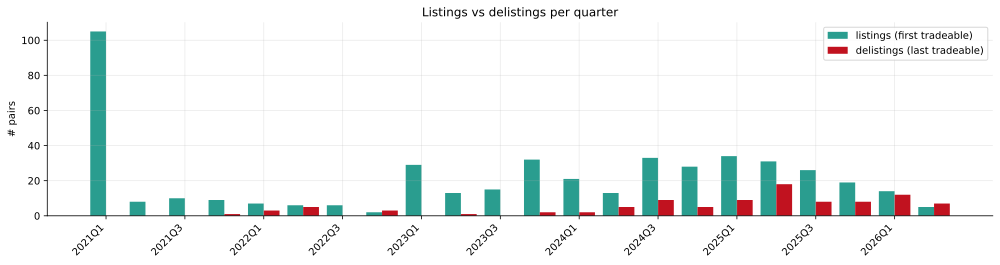

In [3]:
# Listings vs delistings per quarter — the churn behind the stack
first_q = cov['first'].dt.to_period('Q'); last_q = cov[~cov.alive_at_end]['last'].dt.to_period('Q')
lst = first_q.value_counts().sort_index(); dls = last_q.value_counts().sort_index()
qs = pd.period_range(min(lst.index.min(),dls.index.min()), max(lst.index.max(),dls.index.max()), freq='Q')
x = np.arange(len(qs)); w = 0.4
fig, ax = plt.subplots(figsize=(14,3.8))
ax.bar(x-w/2, lst.reindex(qs).fillna(0).values, w, color=TEAL, label='listings (first tradeable)')
ax.bar(x+w/2, dls.reindex(qs).fillna(0).values, w, color=RED, label='delistings (last tradeable)')
ax.set_xticks(x[::2]); ax.set_xticklabels([str(q) for q in qs[::2]], rotation=45, ha='right')
ax.set_ylabel('# pairs'); ax.legend(); ax.set_title('Listings vs delistings per quarter')
plt.tight_layout(); plt.show()

## 2. The cross-sectional funding-APR distribution

Load daily funding **income** (= daily summed rate = APR/365) for every name over its tradeable
window, and look at the **trailing-30d APR** cross-section through time: the median name, the
inter-quartile band, and the **top-decile** (the carry we'd actually chase). Positive ⇒ shorts get
paid (our side).

income panel: 1976 days x 466 names


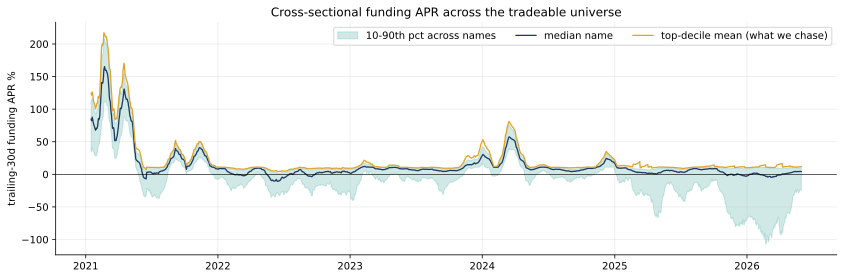

In [4]:
# daily funding-income panel over each name's tradeable window (strictly within coverage)
inc = {}
for s in cov.index:
    f = query.get('perps','binance',s,'funding_rate', columns=['rate'])
    if f.empty: continue
    d = f['rate'].resample('1D').sum()
    d = d.loc[(d.index >= cov.loc[s,'first']) & (d.index <= cov.loc[s,'last'])]
    if len(d): inc[s] = d
INC = pd.DataFrame(inc).sort_index()
INC = INC.loc[INC.index >= '2021-01-01']
apr = INC.rolling(30, min_periods=15).mean() * 365 * 100      # trailing-30d APR %, per name
print(f'income panel: {INC.shape[0]} days x {INC.shape[1]} names')

q = apr.apply(lambda r: pd.Series({'p10':r.quantile(.10),'p50':r.median(),
                                   'p90':r.quantile(.90),'top_decile':r[r>=r.quantile(.90)].mean(),
                                   'n':r.notna().sum()}), axis=1)
fig, ax = plt.subplots(figsize=(14,4.2))
ax.fill_between(q.index, q['p10'], q['p90'], color=TEAL, alpha=0.22, label='10-90th pct across names')
ax.plot(q.index, q['p50'], color=NAVY, lw=1.3, label='median name')
ax.plot(q.index, q['top_decile'], color=AMBER, lw=1.3, label='top-decile mean (what we chase)')
ax.axhline(0,color='k',lw=0.6); ax.set_ylabel('trailing-30d funding APR %'); ax.legend(ncol=3)
ax.set_title('Cross-sectional funding APR across the tradeable universe')
plt.show()

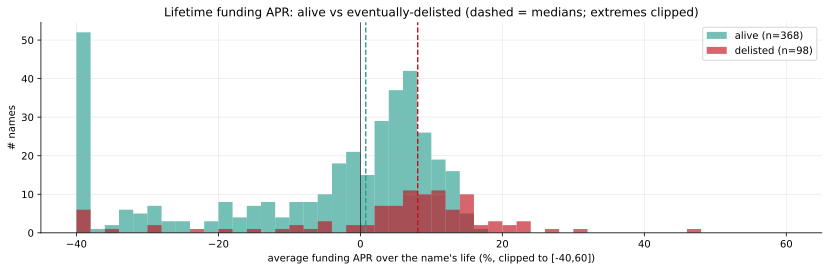

              count  median    p25    p75  below_neg40
alive_at_end                                          
delisted         98    8.08   2.37  13.58            6
alive           368    0.76 -16.63   6.59           50

median funding APR — delisted 8.08% vs alive 0.76% (delisted names ran hotter funding)


In [5]:
# Distribution of each name's average funding APR over its life — alive vs delisted.
# NOTE: the mean is unusable here — newer alts settle every 1-4h and sit pinned at the -2% funding
# cap, so a handful of bleeders reach -100..-350% APR and dominate any average. We lead with the
# MEDIAN (robust) and clip the histogram to [-40,60], counting the extremes that fall outside.
life_apr = (INC.mean()*365*100).rename('avg_apr')
tab = cov.join(life_apr, how='inner').dropna(subset=['avg_apr'])
LO, HI = -40, 60
fig, ax = plt.subplots(figsize=(14,3.8))
bins = np.linspace(LO, HI, 51)
for flag, col, lab in [(True,TEAL,'alive'), (False,RED,'delisted')]:
    v = tab.loc[tab.alive_at_end==flag, 'avg_apr']
    ax.hist(v.clip(LO,HI), bins=bins, color=col, alpha=0.65, label=f'{lab} (n={len(v)})')
    ax.axvline(v.median(), color=col, ls='--', lw=1.4)
ax.axvline(0,color='k',lw=0.6)
ax.set_xlabel('average funding APR over the name\'s life (%, clipped to [-40,60])')
ax.set_ylabel('# names'); ax.legend()
ax.set_title('Lifetime funding APR: alive vs eventually-delisted (dashed = medians; extremes clipped)')
plt.show()
summ = tab.groupby('alive_at_end')['avg_apr'].agg(
    count='count', median='median',
    p25=lambda x: x.quantile(.25), p75=lambda x: x.quantile(.75),
    below_neg40=lambda x: int((x < LO).sum())).round(2)
print(summ.rename(index={True:'alive', False:'delisted'}).to_string())
print(f"\nmedian funding APR — delisted {tab.loc[~tab.alive_at_end,'avg_apr'].median():.2f}% "
      f"vs alive {tab.loc[tab.alive_at_end,'avg_apr'].median():.2f}% "
      f"(delisted names ran hotter funding)")

### The other tail: names that *bleed* funding

Funding carry is violently two-sided. The names with the most **negative** lifetime funding — newer
alts pinned at the -2% settlement cap — would have cost a short-perp/long-spot holder enormously.
These are exactly the seductive-looking, high-|funding| names a naive scanner surfaces, and the
reason v2 needs a health/liquidity veto rather than chasing raw funding magnitude.

In [6]:
bleed = life_apr.nsmallest(12).rename('lifetime_APR_%').to_frame()
bleed['alive_at_end'] = cov['alive_at_end']; bleed['life_days'] = cov['life_days']
print('Most funding-negative names over their life (short-perp holder would PAY this):')
print(bleed.round(1).to_string())

Most funding-negative names over their life (short-perp holder would PAY this):
              lifetime_APR_%  alive_at_end  life_days
sentusdt              -351.0          True        129
0gusdt                -261.3          True        251
ensousdt              -189.7          True        229
bardusdt              -173.5          True        255
cfgusdt               -168.0          True         76
espusdt               -150.1          True        108
chipusdt              -149.9          True         40
funusdt               -148.9         False        379
aigensynusdt          -142.6          True         17
zkpusdt               -140.1          True        144
nomusdt               -139.6          True        242
alpacausdt            -135.8         False        252


## 3. The delisted-name bias — the survivorship trap

The question that matters for backtesting: **how much of the historical high-funding opportunity
came from names that later delisted?** If you build the universe from *today's* live symbols only
(the survivor set), you can't select those names — so a live-only backtest quietly changes the edge.
We quantify it two ways.

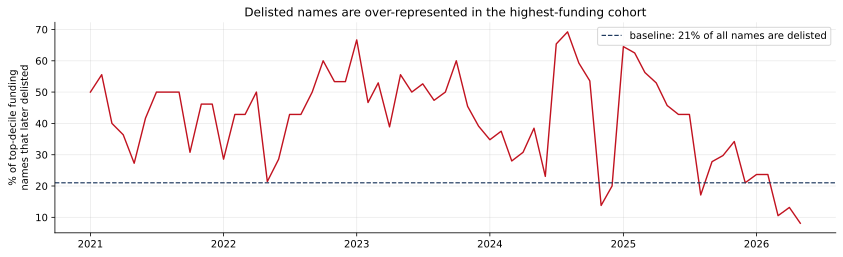

top-decile-funding name-months from eventually-delisted names: 41% (avg)


In [7]:
# (a) Share of top-decile funding 'name-months' contributed by eventually-delisted names.
# Each month, rank active names by trailing-30d APR; take the top decile; what % are delisted names?
monthly = apr.resample('MS').last()               # trailing APR as of each month start
dead_share, n_top = [], []
for m, row in monthly.iterrows():
    r = row.dropna()
    if len(r) < 10: dead_share.append(np.nan); n_top.append(0); continue
    top = r[r >= r.quantile(.90)].index
    dead_share.append(np.mean([not cov.loc[s,'alive_at_end'] for s in top])*100)
    n_top.append(len(top))
ds = pd.Series(dead_share, index=monthly.index)
fig, ax = plt.subplots(figsize=(14,3.8))
ax.plot(ds.index, ds.values, color=RED, lw=1.4)
ax.axhline(float((~cov.alive_at_end).mean()*100), color=NAVY, ls='--', lw=1.2,
           label=f'baseline: {float((~cov.alive_at_end).mean()*100):.0f}% of all names are delisted')
ax.set_ylabel('% of top-decile funding\nnames that later delisted'); ax.legend()
ax.set_title('Delisted names are over-represented in the highest-funding cohort')
plt.show()
print(f'top-decile-funding name-months from eventually-delisted names: {np.nanmean(ds):.0f}% (avg)')

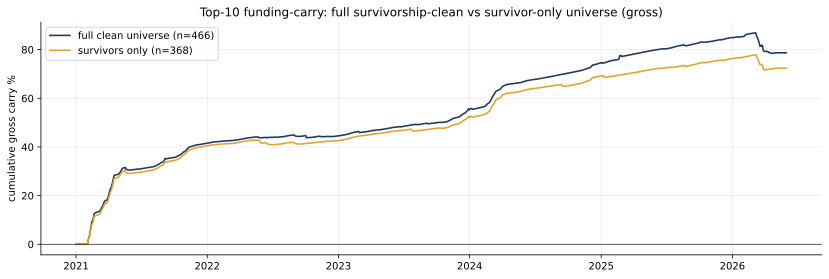

final gross carry — full: 79%  survivor-only: 72%
gap attributable to delisted names: 6%


In [8]:
# (b) Same top-K carry strategy, run on the full clean universe vs a survivor-only universe.
# Monthly rebalance, equal-weight top-K by trailing-30d APR (causal), realized next-month carry.
K = 10
sig = apr.shift(1)                                  # decide on info known at month start
rebal = pd.date_range(INC.index.min(), INC.index.max(), freq='MS')
surv = cov.index[cov.alive_at_end]                  # what a 'live symbols only' study would see
def run(selectable):
    eq = pd.Series(0.0, index=INC.index)
    for i, m in enumerate(rebal[:-1]):
        s0 = sig.loc[:m].iloc[-1] if len(sig.loc[:m]) else None
        if s0 is None: continue
        cand = s0[selectable].dropna(); cand = cand[cand > 0]
        if cand.empty: continue
        picks = cand.nlargest(K).index
        window = (INC.index > m) & (INC.index <= rebal[i+1])
        eq.loc[window] = INC.loc[window, picks].mean(axis=1)     # equal-weight daily carry
    return eq.cumsum()*100
full_eq = run(INC.columns); surv_eq = run(surv)
fig, ax = plt.subplots(figsize=(14,4.2))
ax.plot(full_eq.index, full_eq.values, color=NAVY, lw=1.6, label=f'full clean universe (n={INC.shape[1]})')
ax.plot(surv_eq.index, surv_eq.values, color=AMBER, lw=1.6, label=f'survivors only (n={len(surv)})')
ax.axhline(0,color='k',lw=0.6); ax.set_ylabel('cumulative gross carry %')
ax.legend(); ax.set_title(f'Top-{K} funding-carry: full survivorship-clean vs survivor-only universe (gross)')
plt.show()
print(f'final gross carry — full: {full_eq.iloc[-1]:.0f}%  survivor-only: {surv_eq.iloc[-1]:.0f}%')
print(f'gap attributable to delisted names: {full_eq.iloc[-1]-surv_eq.iloc[-1]:.0f}%')

## Takeaways

- **The universe is not static** — the tradeable set swelled with several listing waves and shed a
  large delisted cohort. A backtest pinned to today's live symbols silently deletes that red band.
- **Delisted names carried more funding**: they're over-represented in the top-decile-funding cohort
  (~41% of top-decile name-months vs a ~21% baseline) and their **median** lifetime APR runs hotter
  than survivors' — high funding often precedes a name's decline, exactly the regime a carry
  harvester is drawn to. (The *mean* is useless here — a few alts pinned at the -2% cap swamp it;
  use the median.)
- **Funding is violently two-sided.** The most negative names bled -100..-350% annualized. Raw
  funding magnitude is not an edge signal on its own — the same scan that finds the best carry finds
  the worst bleeders.
- **So survivorship bias here is real and directional** — read the gap between the two curves in (b).
  Because much of the carry lived in names that later died, a *survivor-only* study **understates**
  the historical gross opportunity, while also hiding the delisting/liquidity risk that came with it.

**Implication for the strategy:** selection and validation must run on the full point-in-time set
(this clean universe), not on currently-listed symbols; and the selection layer (v2) needs a
liquidity/health veto, since both the highest- and lowest-funding names are disproportionately the
ones on the way out. Caveats: 'delisted' is inferred from data coverage (last tradeable > 30d before
the edge); carry here is **gross** (no funding-interval, cost, or capacity haircut); top-K selects
only on positive trailing funding and is a coarse probe, not the v1 rule.